# Task 2: Face Anti-Spoofing (Liveness Detection) — MobileNetV3-Large Fine-Tune (Run 3)
**Course:** COS30082 Applied Machine Learning  
**Task:** Anti-Spoofing / Liveness Detection (2D print & screen presentation attack defense)  
**Model:** `MobileNetV3FAS` — MobileNetV3-Large pretrained ImageNet backbone (full fine-tuning) with Auxiliary Fourier Supervision generator (`FTGenerator` on stride-8 feature map, 40 channels).  
**Training:** 30 epochs, AdamW with 2-group learning rate (backbone lr=3e-4, head/FT lr=1e-3), Cosine Annealing scheduler, multi-task loss ($\mathcal{L}_{\text{CE}} + 0.5\mathcal{L}_{\text{FT}}$).

---
### Technical Specifications
- **Input Resolution:** $80 \times 80$ face crop, normalized to $[-1, 1]$ (internally converted to ImageNet normalization)
- **Supervision:** Combined Cross-Entropy classification loss + Mean Squared Error Fourier supervision ($10 \times 10$)
- **Target Classes:** Binary classification: `0 = live`, `1 = spoof`
- **Evaluation Metrics:** APCER, BPCER, ACER, and ROC / AUC on intra-test split
- **Baseline (Run 2 From Scratch):** Test ACER 8.70%, Test AUC 0.9833

---
### How to run on vast.ai
1. Upload **`fas-code.zip`** and this notebook to **`/workspace`** (Jupyter upload button or `scp`).
2. Instance: 1 GPU (any recent NVIDIA, ≥8 GB VRAM), **≥8 vCPU**, ≥16 GB RAM, **≥40 GB disk**.
3. Run all cells top to bottom. Cell 1 unzips the code, cell 2 builds an isolated Python 3.12 env for data prep (MediaPipe 0.10.14), the rest trains in this kernel.
4. Download **`/workspace/liveness_outputs_ft.zip`** at the end.

Layout: code → `/workspace/fas-code`, data → `/workspace/fas_data_v2` (+ HF cache `/workspace/.cache/fas_hf`), outputs → `/workspace/liveness_run_ft/{checkpoints,results}`.


## Section 0 – Setup & Imports


In [1]:
# ── Unzip uploaded code ─────────────────────────────────────────────────────
import os, zipfile
from pathlib import Path

WORKSPACE = Path(os.environ.get("WORKSPACE_DIR", "/workspace"))
CODE_ZIP = WORKSPACE / "fas-code.zip"
CODE_DIR = WORKSPACE / "fas-code"

if not (CODE_DIR / "liveness" / "fas_common.py").exists():
    if not CODE_ZIP.exists():
        raise FileNotFoundError(f"Upload fas-code.zip to {WORKSPACE} first.")
    with zipfile.ZipFile(CODE_ZIP) as z:
        z.extractall(CODE_DIR)
    # Handle zips that contain a single top-level folder
    if not (CODE_DIR / "liveness").exists():
        inner = [p for p in CODE_DIR.iterdir() if (p / "liveness" / "fas_common.py").exists()]
        if inner:
            CODE_DIR = inner[0]
required = ["liveness/__init__.py", "liveness/fas_common.py", "liveness/fas_model.py", "utils/prepare_fas_data.py"]
missing = [r for r in required if not (CODE_DIR / r).exists()]
if missing:
    raise FileNotFoundError(f"Missing in {CODE_DIR}: {missing}")
os.environ["FAS_CODE_DIR"] = str(CODE_DIR)
print(f"Code ready at {CODE_DIR}")


Code ready at /workspace/fas-code


In [2]:
# ── Hugging Face token (optional, speeds up / avoids rate limits on download) ──
# The token is typed in at run time and kept only in this kernel's environment.
# It is NEVER written into the notebook or any file. Leave the prompt empty to skip.
import os
from getpass import getpass

if not os.environ.get("HF_TOKEN"):
    _tok = getpass("Hugging Face token (hf_..., Enter to skip): ").strip()
    if _tok:
        os.environ["HF_TOKEN"] = _tok
    del _tok
print("HF_TOKEN set:", bool(os.environ.get("HF_TOKEN")))


Hugging Face token (hf_..., Enter to skip):  ········


HF_TOKEN set: True


In [3]:
# ── Isolated Python 3.12 env for data prep (MediaPipe 0.10.14 needs numpy<2, Python<=3.12) ──
import sys, subprocess, os
from pathlib import Path

PREP_VENV = WORKSPACE / "prep_venv"
PREP_PY = WORKSPACE / "prep_venv" / ("bin" if os.name != "nt" else "Scripts") / "python"

def sh(cmd):
    print("$", " ".join(map(str, cmd)))
    subprocess.run(list(map(str, cmd)), check=True)

print(f"Kernel Python {sys.version.split()[0]}")
if os.name == "nt":
    print("On Windows: data prep uses current Python environment (prep_venv skipped).")
else:
    # Kernel-side packages for training/eval (torch is preinstalled on vast PyTorch images)
    sh([sys.executable, "-m", "pip", "install", "-q", "scikit-learn", "matplotlib", "opencv-python-headless", "uv"])
    if not PREP_PY.exists():
        sh([sys.executable, "-m", "uv", "venv", "--python", "3.12", str(PREP_VENV)])
        sh([sys.executable, "-m", "uv", "pip", "install", "--python", PREP_PY,
            "torch", "--index-url", "https://download.pytorch.org/whl/cpu"])
        sh([sys.executable, "-m", "uv", "pip", "install", "--python", PREP_PY,
            "mediapipe==0.10.14", "protobuf>=4.25.3,<5", "numpy<2", "opencv-python-headless<4.12",
            "huggingface_hub", "pyarrow<18", "matplotlib", "matplotlib-inline"])  # pyarrow>=18 / opencv>=4.12 need numpy 2
    env_prep = dict(os.environ, MPLBACKEND="Agg")
    chk = subprocess.run([str(PREP_PY), "-c",
                          "import sys, numpy, cv2, torch, pyarrow, matplotlib, huggingface_hub, mediapipe as mp; "
                          "mp.solutions.face_detection.FaceDetection(model_selection=0); "
                          "print('prep env OK | python', sys.version.split()[0], '| mediapipe', mp.__version__, "
                          "'| numpy', numpy.__version__)"],
                         env=env_prep, capture_output=True, text=True)
    print(chk.stdout.strip() or chk.stderr[-3000:])
    if chk.returncode != 0:
        raise RuntimeError("Prep env check failed (see message above).")


Kernel Python 3.12.15
$ /venv/main/bin/python -m pip install -q scikit-learn matplotlib opencv-python-headless uv


Using CPython 3.12.15 interpreter at: /venv/main/bin/python
Creating virtual environment at: prep_venv
Activate with: source prep_venv/bin/activate
Using Python 3.12.15 environment at: prep_venv


$ /venv/main/bin/python -m uv venv --python 3.12 /workspace/prep_venv
$ /venv/main/bin/python -m uv pip install --python /workspace/prep_venv/bin/python torch --index-url https://download.pytorch.org/whl/cpu


Resolved 10 packages in 139ms
Prepared 10 packages in 1.13s
Installed 10 packages in 2.14s
 + filelock==3.32.3
 + fsspec==2026.7.0
 + jinja2==3.1.6
 + markupsafe==3.0.3
 + mpmath==1.3.0
 + networkx==3.6.1
 + setuptools==78.1.0
 + sympy==1.14.0
 + torch==2.14.1+cpu
 + typing-extensions==4.16.0


$ /venv/main/bin/python -m uv pip install --python /workspace/prep_venv/bin/python mediapipe==0.10.14 protobuf>=4.25.3,<5 numpy<2 opencv-python-headless<4.12 huggingface_hub pyarrow<18 matplotlib matplotlib-inline


Using Python 3.12.15 environment at: prep_venv
Resolved 43 packages in 199ms
Prepared 40 packages in 1.29s
Installed 40 packages in 594ms
 + absl-py==2.5.1
 + anyio==4.15.1
 + attrs==26.1.0
 + cffi==2.1.1
 + click==8.5.0
 + contourpy==1.3.3
 + cycler==0.12.1
 + flatbuffers==25.12.19
 + fonttools==4.67.0
 + h11==0.16.0
 + hf-xet==1.7.0
 + httpcore2==2.13.1
 + httpx2==2.13.1
 + huggingface-hub==2.2.0
 + idna==3.20
 + jax==0.7.1
 + jaxlib==0.7.1
 + kiwisolver==1.5.1
 + matplotlib==3.11.2
 + matplotlib-inline==0.2.2
 + mediapipe==0.10.14
 + ml-dtypes==0.5.4
 + numpy==1.26.4
 + opencv-contrib-python==4.11.0.86
 + opencv-python-headless==4.11.0.86
 + opt-einsum==3.4.0
 + packaging==26.3
 + pillow==13.0.0
 + protobuf==4.25.9
 + pyarrow==17.0.0
 + pycparser==3.11
 + pyparsing==3.3.3
 + python-dateutil==2.9.0.post0
 + pyyaml==6.0.3
 + scipy==1.17.1
 + six==1.17.0
 + sounddevice==0.5.6
 + tqdm==4.70.1
 + traitlets==5.16.1
 + truststore==0.10.5


prep env OK | python 3.12.15 | mediapipe 0.10.14 | numpy 1.26.4


In [4]:
import os
import sys
import json
import random
import shutil
import subprocess
from pathlib import Path

# ── Use a single GPU (GPU 0) ──────────────────────────────────────────────────
if "CUDA_VISIBLE_DEVICES" not in os.environ:
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import roc_curve, auc, confusion_matrix

cv2.setNumThreads(0)   # avoid OpenCV thread oversubscription inside DataLoader workers

REPO_ROOT = Path(os.environ.get("FAS_CODE_DIR", "/workspace/fas-code"))
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print(f"Code root: {REPO_ROOT}")

from liveness.fas_model import MultiFTNet, MobileNetV3FAS, build_model, get_kernel
from liveness.fas_common import (
    INPUT_SIZE,
    FT_SIZE,
    LIVE_INDEX,
    CLASS_NAMES,
    resize_face,
    to_tensor,
    prepare_face,
    generate_ft_target,
    load_config,
)

# ── Paths ─────────────────────────────────────────────────────────────────────
WORKSPACE = Path(os.environ.get("WORKSPACE_DIR", "/workspace"))
WORK_DIR = WORKSPACE / "liveness_run_ft"
DATA_DIR = Path(os.environ.get("FAS_DATA_DIR", WORKSPACE / "fas_data_v2"))
HF_CACHE = Path(os.environ.get("FAS_HF_CACHE", WORKSPACE / ".cache" / "fas_hf"))
PREP_PY = WORKSPACE / "prep_venv" / "bin" / "python"

CKPT_DIR = WORK_DIR / "checkpoints"
RESULT_DIR = WORK_DIR / "results"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

# ── Device Selection ──────────────────────────────────────────────────────────
if torch.cuda.is_available():
    DEVICE = torch.device("cuda:0")
    gpu_name = torch.cuda.get_device_name(0)
    gpu_count = torch.cuda.device_count()
    print(f"Using device: {DEVICE} ({gpu_name}) | Visible GPUs: {gpu_count} (pinned strictly to GPU 0)")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    print(f"Using device: {DEVICE}")
else:
    DEVICE = torch.device("cpu")
    print(f"Using device: {DEVICE}")
print(f"CPU cores: {os.cpu_count()} | Data dir: {DATA_DIR} | Outputs: {WORK_DIR}")

# ── Smoke Mode & Hyperparameters ──────────────────────────────────────────────
SMOKE = os.environ.get("FAS_SMOKE") == "1"
if SMOKE:
    print("[INFO] Running in SMOKE mode (FAS_SMOKE=1)")
    EPOCHS = 1
    BATCH_SIZE = 32
    NUM_WORKERS = 0
    MAX_SAMPLES = 512
else:
    EPOCHS = 30
    BATCH_SIZE = 256
    NUM_WORKERS = 0 if os.name == "nt" else min(8, os.cpu_count() or 1)
    MAX_SAMPLES = None

LR = 1e-3
WEIGHT_DECAY = 5e-4
FT_WEIGHT = 0.5


Code root: /workspace/fas-code
Using device: cuda:0 (NVIDIA GeForce RTX 4060 Ti) | Visible GPUs: 1 (pinned strictly to GPU 0)
CPU cores: 24 | Data dir: /workspace/fas_data_v2 | Outputs: /workspace/liveness_run_ft


## Section 0b – Data Preparation (download + calibrate + build NPZ)


In [5]:
# Runs utils/prepare_fas_data.py once (skipped if DATA_DIR already has meta.json + npz files from 46 shards with clean val)
import time, subprocess, json

# Máy 40 GB không đủ chỗ giữ toàn bộ cache cho 46 shard
DELETE_SHARDS_AFTER_PROCESSING = True

# HF Token để tăng tốc tải và tránh bị rate limit (lấy từ biến môi trường, Kaggle Secrets, hoặc điền trực tiếp)
# Tạo token miễn phí tại https://huggingface.co/settings/tokens (Read token)
HF_TOKEN = ""  # Điền trực tiếp dạng "hf_..." nếu không dùng biến môi trường
if not HF_TOKEN:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")
if not HF_TOKEN:
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        pass

needed = ["meta.json", "train.npz", "val.npz", "test.npz"]
meta_file = DATA_DIR / "meta.json"
meta_existing = json.loads(meta_file.read_text(encoding="utf-8")) if meta_file.exists() else {}
prep_args_existing = meta_existing.get("prep_args", {})

if (
    all((DATA_DIR / f).exists() for f in needed)
    and prep_args_existing.get("n_train_shards") == 46
    and "val_mode" in meta_existing
):
    print(f"Prepared data (46 shards, clean val) found in {DATA_DIR}; skipping preparation.")
else:
    candidates = [REPO_ROOT / "utils" / "prepare_fas_data.py"]
    prep_script = next((c for c in candidates if c.exists()), None)
    if prep_script is None:
        raise RuntimeError(f"prepare_fas_data.py not found in: {[str(c) for c in candidates]}")
    env = dict(os.environ, MPLBACKEND="Agg")
    if HF_TOKEN:
        env["HF_TOKEN"] = HF_TOKEN.strip()
        print(f"HF_TOKEN detected ({HF_TOKEN.strip()[:6]}...): authenticated requests enabled.")
    else:
        print("HF_TOKEN not set: running with unauthenticated HF requests.")
    prep_python = str(PREP_PY) if PREP_PY.exists() else sys.executable
    cmd = [prep_python, "-u", str(prep_script), "--out-dir", str(DATA_DIR), "--cache-dir", str(HF_CACHE)]
    if DELETE_SHARDS_AFTER_PROCESSING:
        cmd.append("--delete-after-processing")
    if SMOKE:
        cmd += ["--n-train-shards", "1", "--max-rows-per-shard", "300", "--calib-n", "100"]
    print("Running:", " ".join(cmd))
    t0 = time.time()
    proc = subprocess.Popen(cmd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    log_lines = []
    for line in proc.stdout:
        print(line, end="")
        log_lines.append(line)
    proc.wait()
    (RESULT_DIR / "liveness_prepare.log").write_text("".join(log_lines), encoding="utf-8")
    if proc.returncode != 0:
        raise RuntimeError(f"Data preparation failed (exit code {proc.returncode}). See log above.")
    print(f"Data preparation finished in {(time.time() - t0) / 60:.1f} min.")


HF_TOKEN detected (hf_wnJ...): authenticated requests enabled.
Running: /workspace/prep_venv/bin/python -u /workspace/fas-code/utils/prepare_fas_data.py --out-dir /workspace/fas_data_v2 --cache-dir /workspace/.cache/fas_hf --delete-after-processing
  CelebA-Spoof Dataset Preparation for Face Anti-Spoofing (FAS)
  Out Dir: /workspace/fas_data_v2
  Cache Dir: /workspace/.cache/fas_hf
  Seed: 42  |  Train Shards (target): 46/93
  Delete Parquet Shards After Processing: True

[1] Scanning cache for existing train shards...
  Found 0 train shards in cache: []

[Step 0] Inspecting first shard for schema and subject ID...
  [download] data/train-00000-of-00093.parquet...
  [Step 0] First 5 cropped_image['path'] values: [None, None, None, None, None]
  [Step 0] Cannot parse subject_id from cropped_image['path'] (values are None or do not match regex).
  [Step 0] Active validation strategy: Branch 2 (held-out shards split).
  [WARNING] Val split uses held-out shards. This only approximates subj

## Section 1 – Data Exploration (EDA)


  CelebA-Spoof Dataset Summary (from meta.json)
  Validation Mode: heldout_shards
  Val shards: [14, 81]
  Train shards: [0, 2, 3, 4, 5, 6, 7, 9, 11, 13, 17, 18, 21, 22, 23, 25, 26, 28, 29, 30, 32, 35, 36, 39, 44, 47, 49, 54, 55, 58, 65, 69, 70, 71, 72, 76, 77, 80, 83, 85, 86, 87, 88, 89, 91, 92]
  Cache / Download: 1 cached, 58 downloaded (26.686 GB), freed: 22.08 GB
  Calibrated crop: {'scale_w': 0.88, 'scale_h': 1.33, 'shift_x': -0.03, 'shift_y': -0.13}
-----------------------------------------------------------------
  Split           Total     Live (0)    Spoof (1)     Live %
-----------------------------------------------------------------
  train         241,463       79,551      161,912      32.9%
  val            10,511        3,388        7,123      32.2%
  test           66,643       19,694       46,949      29.6%


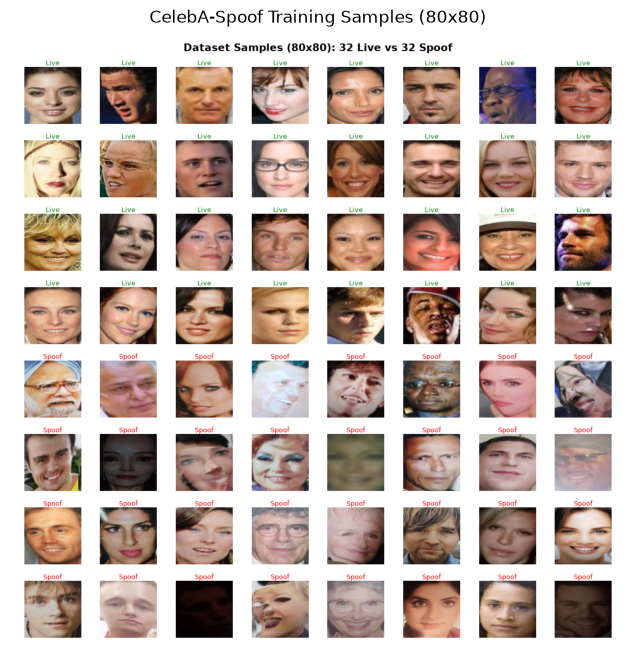

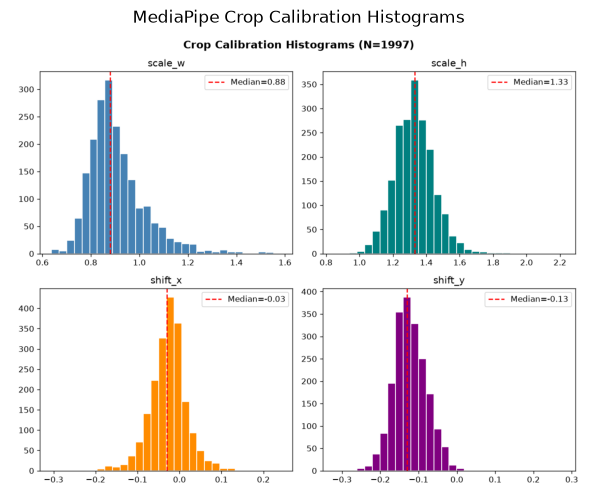

In [6]:
meta_path = DATA_DIR / "meta.json"
meta = {}
if meta_path.exists():
    with open(meta_path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    print("=" * 65)
    print("  CelebA-Spoof Dataset Summary (from meta.json)")
    print("=" * 65)
    val_mode = meta.get("val_mode", "unknown")
    print(f"  Validation Mode: {val_mode}")
    if val_mode == "heldout_shards":
        print(f"  Val shards: {meta.get('val_shards', [])}")
    elif val_mode == "subject":
        print(f"  Subjects: {meta.get('train_subjects_count', 0)} train vs {meta.get('val_subjects_count', 0)} val")
    print(f"  Train shards: {meta.get('train_shards', [])}")
    dl_stats = meta.get("download_stats", {})
    if dl_stats:
        print(f"  Cache / Download: {dl_stats.get('cached_files', 0)} cached, {dl_stats.get('downloaded_files', 0)} downloaded ({dl_stats.get('downloaded_gb', 0)} GB), freed: {dl_stats.get('freed_gb', 0)} GB")
    print(f"  Calibrated crop: {meta.get('crop_cfg', {})}")
    print("-" * 65)
    print(f"  {'Split':<10} {'Total':>10} {'Live (0)':>12} {'Spoof (1)':>12} {'Live %':>10}")
    print("-" * 65)
    for sp, st in meta.get("splits", {}).items():
        pct = (st["live"] / st["total"] * 100) if st["total"] > 0 else 0
        print(f"  {sp:<10} {st['total']:>10,} {st['live']:>12,} {st['spoof']:>12,} {pct:>9.1f}%")
    print("=" * 65)
else:
    print(f"meta.json not found at {meta_path}; reading directly from npz files.")

# Show sample images if available
samples_file = DATA_DIR / "samples.png"
if samples_file.exists():
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(cv2.imread(str(samples_file)), cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("CelebA-Spoof Training Samples (80x80)", fontsize=12)
    plt.show()

calib_hist_file = DATA_DIR / "calib_hist.png"
if calib_hist_file.exists():
    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(cv2.imread(str(calib_hist_file)), cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("MediaPipe Crop Calibration Histograms", fontsize=12)
    plt.show()


## Section 2 – Datasets & DataLoaders


In [7]:
def augment_bgr(img: np.ndarray) -> np.ndarray:
    """Data augmentations for face anti-spoofing in BGR format."""
    h, w = img.shape[:2]
    # 1. Random Resized Crop (area 0.9 - 1.0, aspect ratio 0.95 - 1.05)
    area = h * w
    target_area = random.uniform(0.9, 1.0) * area
    aspect_ratio = random.uniform(0.95, 1.05)
    crop_w = int(round(np.sqrt(target_area * aspect_ratio)))
    crop_h = int(round(np.sqrt(target_area / aspect_ratio)))
    crop_w = min(w, max(1, crop_w))
    crop_h = min(h, max(1, crop_h))
    x0 = random.randint(0, w - crop_w)
    y0 = random.randint(0, h - crop_h)
    cropped = img[y0:y0+crop_h, x0:x0+crop_w]
    img = resize_face(cropped)

    # 2. Horizontal Flip (p=0.5)
    if random.random() < 0.5:
        img = cv2.flip(img, 1)

    # 3. Brightness / Contrast (+-0.2)
    alpha = 1.0 + random.uniform(-0.2, 0.2)
    beta = random.uniform(-0.2, 0.2) * 255.0
    img = np.clip(img.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)

    # 4. Saturation (+-0.1) via HSV
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    sat_scale = 1.0 + random.uniform(-0.1, 0.1)
    hsv[:, :, 1] = np.clip(hsv[:, :, 1] * sat_scale, 0, 255)
    img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    # 5. Gaussian blur k=3 (p=0.1)
    if random.random() < 0.1:
        img = cv2.GaussianBlur(img, (3, 3), 0)

    return img


class FASDataset(Dataset):
    """Loads 80x80 BGR face arrays from NPZ and produces (tensor, ft_target, label)."""
    def __init__(self, npz_path: Path, is_train: bool = False, max_samples: int | None = None):
        self.is_train = is_train
        data = np.load(npz_path)
        self.images = data["images"]
        self.labels = data["labels"]
        if max_samples is not None and len(self.labels) > max_samples:
            self.images = self.images[:max_samples]
            self.labels = self.labels[:max_samples]
        n_live = int(np.sum(self.labels == 0))
        n_spoof = int(np.sum(self.labels == 1))
        print(f"Loaded {npz_path.name}: {len(self.labels):,} images (Live: {n_live:,}, Spoof: {n_spoof:,})")

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.is_train:
            img = augment_bgr(img)
        ft = generate_ft_target(img)
        x = to_tensor(img)
        return x, ft, label


print("=== Initializing Datasets ===")
train_ds = FASDataset(DATA_DIR / "train.npz", is_train=True, max_samples=MAX_SAMPLES)
val_ds = FASDataset(DATA_DIR / "val.npz", is_train=False, max_samples=MAX_SAMPLES)
test_ds = FASDataset(DATA_DIR / "test.npz", is_train=False, max_samples=MAX_SAMPLES)

# WeightedRandomSampler for class balance
train_labels = train_ds.labels
class_counts = np.bincount(train_labels, minlength=2)
class_weights = 1.0 / np.maximum(class_counts, 1)
sample_weights = class_weights[train_labels]
sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(train_labels),
    replacement=True,
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=NUM_WORKERS > 0,
)
print("DataLoaders initialized successfully.")


=== Initializing Datasets ===
Loaded train.npz: 241,463 images (Live: 79,551, Spoof: 161,912)
Loaded val.npz: 10,511 images (Live: 3,388, Spoof: 7,123)
Loaded test.npz: 66,643 images (Live: 19,694, Spoof: 46,949)
DataLoaders initialized successfully.


## Section 3 – MobileNetV3-Large FAS Architecture (Fine-Tuning)


In [8]:
# ── Build MobileNetV3-Large FAS Model with ImageNet Pretrained Backbone ─────
model = build_model({"arch": "MobileNetV3Large-FT", "num_classes": len(CLASS_NAMES)}, pretrained=True)
model = model.to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
backbone_params = sum(p.numel() for p in model.stem_to_s8.parameters()) + sum(p.numel() for p in model.rest.parameters())
head_ft_params = sum(p.numel() for p in model.head.parameters()) + sum(p.numel() for p in model.FTGenerator.parameters())

print(f"Architecture: MobileNetV3Large-FT (ImageNet Pretrained)")
print(f"Device: {DEVICE}")
print(f"Total Parameters: {n_params:,} ({n_params/1e6:.2f}M)")
print(f"Backbone Parameters (fine-tune lr=3e-4): {backbone_params:,} ({backbone_params/1e6:.2f}M)")
print(f"Head + FTGenerator Parameters (lr=1e-3): {head_ft_params:,} ({head_ft_params/1e6:.2f}M)")


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 253MB/s]


Architecture: MobileNetV3Large-FT (ImageNet Pretrained)
Device: cuda:0
Total Parameters: 3,216,181 (3.22M)
Backbone Parameters (fine-tune lr=3e-4): 2,971,952 (2.97M)
Head + FTGenerator Parameters (lr=1e-3): 244,229 (0.24M)


## Section 4 – Training (MobileNetV3FAS + Auxiliary Fourier Loss)


In [9]:
criterion_ce = nn.CrossEntropyLoss()
criterion_mse = nn.MSELoss()

backbone_params = list(model.stem_to_s8.parameters()) + list(model.rest.parameters())
head_ft_params = list(model.head.parameters()) + list(model.FTGenerator.parameters())

optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": 3e-4, "weight_decay": WEIGHT_DECAY},
    {"params": head_ft_params, "lr": 1e-3, "weight_decay": WEIGHT_DECAY},
])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def train_epoch(model, loader, optimizer, device, ft_weight=0.5):
    model.train()
    total_loss, total_ce, total_ft = 0.0, 0.0, 0.0
    correct, total = 0, 0
    for imgs, fts, labels in loader:
        imgs, fts, labels = imgs.to(device), fts.to(device), labels.to(device)
        optimizer.zero_grad()
        logits, ft_pred = model(imgs)
        loss_ce = criterion_ce(logits, labels)
        loss_ft = criterion_mse(ft_pred, fts)
        loss = (1.0 - ft_weight) * loss_ce + ft_weight * loss_ft
        loss.backward()
        optimizer.step()

        bs = imgs.size(0)
        total_loss += loss.item() * bs
        total_ce += loss_ce.item() * bs
        total_ft += loss_ft.item() * bs
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += bs
    return total_loss / total, total_ce / total, total_ft / total, correct / total

@torch.no_grad()
def evaluate_model(model, loader, device):
    model.eval()
    all_probs = []
    all_labels = []
    total_loss = 0.0
    total = 0
    for imgs, _, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        loss = criterion_ce(logits, labels)
        probs = F.softmax(logits, dim=1)[:, LIVE_INDEX]
        all_probs.extend(probs.cpu().numpy().tolist())
        all_labels.extend(labels.cpu().numpy().tolist())
        bs = imgs.size(0)
        total_loss += loss.item() * bs
        total += bs
    return total_loss / total, np.array(all_probs), np.array(all_labels)

def calculate_acer(p_live, labels, threshold):
    is_real = p_live >= threshold
    spoof_mask = (labels == 1)
    apcer = float(np.mean(is_real[spoof_mask])) if np.sum(spoof_mask) > 0 else 0.0
    live_mask = (labels == 0)
    bpcer = float(np.mean(~is_real[live_mask])) if np.sum(live_mask) > 0 else 0.0
    acer = (apcer + bpcer) / 2.0
    return apcer, bpcer, acer

def select_threshold(p_live, labels):
    unique_th = np.unique(p_live)
    best_t = 0.5
    min_acer = float("inf")
    for t in unique_th:
        _, _, acer = calculate_acer(p_live, labels, t)
        if acer < min_acer:
            min_acer = acer
            best_t = float(t)
        elif acer == min_acer and t < best_t:
            best_t = float(t)
    return best_t, min_acer

best_val_auc = -1.0
best_val_acer = float("inf")
best_val_thresh = 0.5
history = {
    "epoch": [], "train_loss": [], "train_acc": [],
    "val_loss": [], "val_auc": [], "val_acer": [], "val_thresh": [],
    "epoch_time_s": [],
}

best_ckpt_path = CKPT_DIR / "liveness_best.pth"

print(f"Training MobileNetV3FAS for {EPOCHS} epochs on {DEVICE}...")
import time
epoch_times = []
for epoch in range(1, EPOCHS + 1):
    t_epoch = time.time()
    tr_loss, tr_ce, tr_ft, tr_acc = train_epoch(model, train_loader, optimizer, DEVICE, ft_weight=FT_WEIGHT)
    val_loss, val_probs, val_lbls = evaluate_model(model, val_loader, DEVICE)
    scheduler.step()
    t_elapsed = time.time() - t_epoch
    epoch_times.append(t_elapsed)

    val_y_live = (val_lbls == LIVE_INDEX).astype(int)
    fpr, tpr, _ = roc_curve(val_y_live, val_probs)
    val_auc = float(auc(fpr, tpr)) if len(np.unique(val_y_live)) > 1 else 0.5
    val_th, val_acer = select_threshold(val_probs, val_lbls)

    history["epoch"].append(epoch)
    history["train_loss"].append(round(tr_loss, 4))
    history["train_acc"].append(round(tr_acc * 100, 2))
    history["val_loss"].append(round(val_loss, 4))
    history["val_auc"].append(round(val_auc, 4))
    history["val_acer"].append(round(val_acer * 100, 2))
    history["val_thresh"].append(round(val_th, 4))
    history["epoch_time_s"].append(round(t_elapsed, 2))

    is_best = val_auc > best_val_auc
    if is_best:
        best_val_auc = val_auc
        best_val_acer = val_acer
        best_val_thresh = val_th
        torch.save(model.state_dict(), best_ckpt_path)
        marker = " <- BEST"
    else:
        marker = ""

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {tr_loss:.4f} (Acc: {tr_acc*100:.1f}%) | "
        f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val ACER: {val_acer*100:.2f}% | {t_elapsed:.0f}s{marker}"
    )

with open(RESULT_DIR / "liveness_history.json", "w") as f:
    json.dump(history, f, indent=2)
print(f"Best checkpoint saved to: {best_ckpt_path} (Val AUC: {best_val_auc:.4f}, Val ACER: {best_val_acer*100:.2f}%)")


Training MobileNetV3FAS for 30 epochs on cuda:0...
Epoch 01/30 | Train Loss: 0.0688 (Acc: 95.1%) | Val Loss: 0.0976 | Val AUC: 0.9974 | Val ACER: 2.34% | 59s <- BEST
Epoch 02/30 | Train Loss: 0.0351 (Acc: 97.5%) | Val Loss: 0.0477 | Val AUC: 0.9986 | Val ACER: 1.57% | 58s <- BEST
Epoch 03/30 | Train Loss: 0.0270 (Acc: 98.1%) | Val Loss: 0.0361 | Val AUC: 0.9990 | Val ACER: 1.38% | 58s <- BEST
Epoch 04/30 | Train Loss: 0.0232 (Acc: 98.3%) | Val Loss: 0.0323 | Val AUC: 0.9992 | Val ACER: 1.16% | 58s <- BEST
Epoch 05/30 | Train Loss: 0.0190 (Acc: 98.7%) | Val Loss: 0.0419 | Val AUC: 0.9994 | Val ACER: 1.09% | 58s <- BEST
Epoch 06/30 | Train Loss: 0.0175 (Acc: 98.8%) | Val Loss: 0.0489 | Val AUC: 0.9992 | Val ACER: 1.21% | 58s
Epoch 07/30 | Train Loss: 0.0154 (Acc: 98.9%) | Val Loss: 0.0357 | Val AUC: 0.9995 | Val ACER: 0.94% | 58s <- BEST
Epoch 08/30 | Train Loss: 0.0137 (Acc: 99.1%) | Val Loss: 0.0358 | Val AUC: 0.9994 | Val ACER: 0.89% | 58s
Epoch 09/30 | Train Loss: 0.0124 (Acc: 99.2%)

## Section 5 – Metrics & Evaluation (ROC, AUC, ACER)


=== Loading Best Checkpoint for Evaluation ===
Selected Optimal Threshold on Val: 0.1678 (Val ACER: 0.55%)
  Test Evaluation Results (N = 66,643)
  Threshold : 0.1678
  Test AUC  : 0.9795
  APCER     : 25.11% (Spoof classified as Real)
  BPCER     : 0.55% (Live classified as Fake)
  ACER      : 12.83%


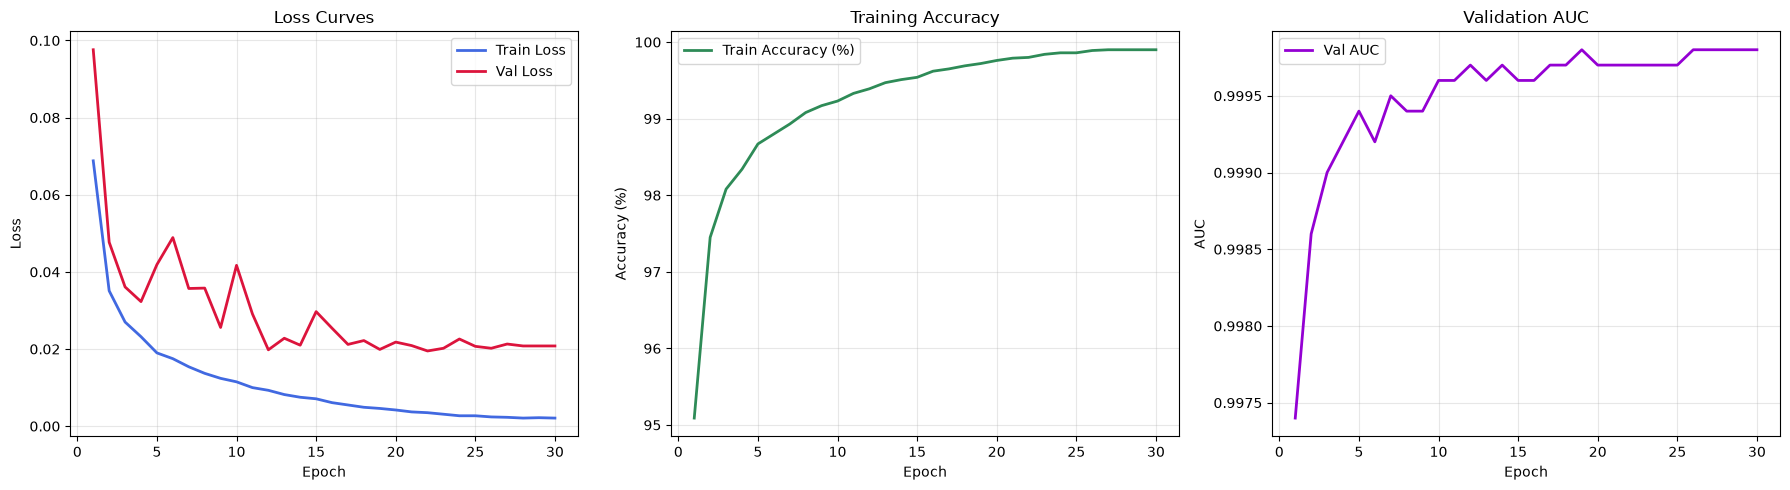

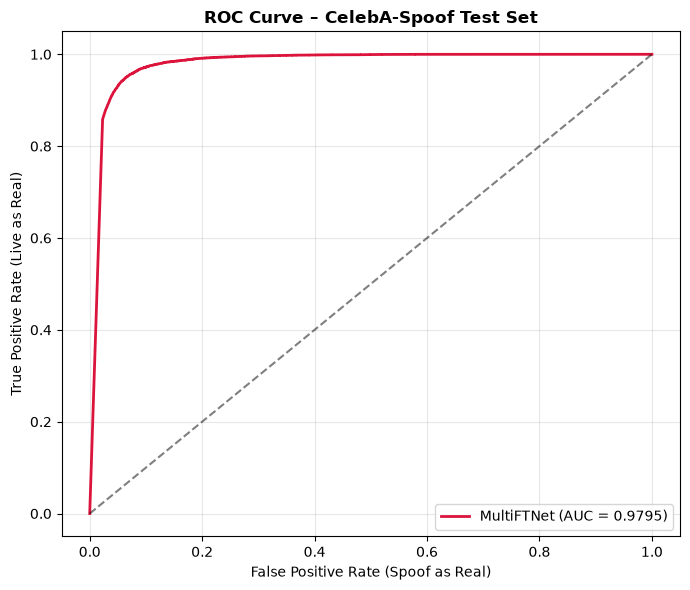

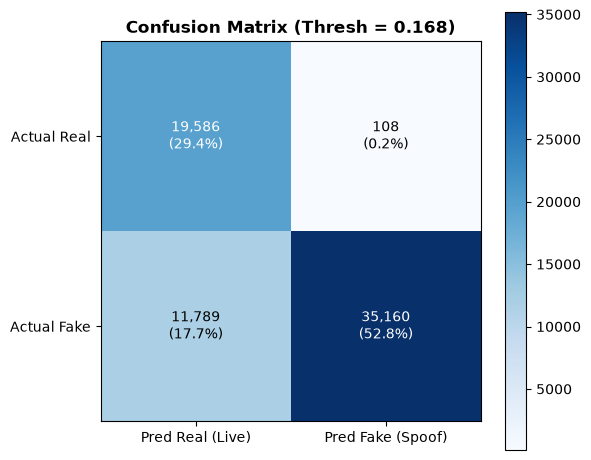

Saved evaluation metrics to: /workspace/liveness_run_ft/results/liveness_metrics.json


In [10]:
print("=== Loading Best Checkpoint for Evaluation ===")
model.load_state_dict(torch.load(best_ckpt_path, map_location=DEVICE))
model.eval()

# Threshold chosen strictly on Validation set
val_loss, val_probs, val_lbls = evaluate_model(model, val_loader, DEVICE)
selected_threshold, val_acer_at_th = select_threshold(val_probs, val_lbls)
print(f"Selected Optimal Threshold on Val: {selected_threshold:.4f} (Val ACER: {val_acer_at_th*100:.2f}%)")

# Evaluate on Test set using the Val threshold
test_loss, test_probs, test_lbls = evaluate_model(model, test_loader, DEVICE)
test_y_live = (test_lbls == LIVE_INDEX).astype(int)
test_fpr, test_tpr, _ = roc_curve(test_y_live, test_probs)
test_auc = float(auc(test_fpr, test_tpr)) if len(np.unique(test_y_live)) > 1 else 0.5
test_apcer, test_bpcer, test_acer = calculate_acer(test_probs, test_lbls, selected_threshold)

print("=" * 60)
print(f"  Test Evaluation Results (N = {len(test_lbls):,})")
print("=" * 60)
print(f"  Threshold : {selected_threshold:.4f}")
print(f"  Test AUC  : {test_auc:.4f}")
print(f"  APCER     : {test_apcer*100:.2f}% (Spoof classified as Real)")
print(f"  BPCER     : {test_bpcer*100:.2f}% (Live classified as Fake)")
print(f"  ACER      : {test_acer*100:.2f}%")
print("=" * 60)

# 1. Training Curves Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ep = history["epoch"]
axes[0].plot(ep, history["train_loss"], label="Train Loss", color="royalblue", lw=2)
axes[0].plot(ep, history["val_loss"], label="Val Loss", color="crimson", lw=2)
axes[0].set_title("Loss Curves"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")

axes[1].plot(ep, history["train_acc"], label="Train Accuracy (%)", color="seagreen", lw=2)
axes[1].set_title("Training Accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)")

axes[2].plot(ep, history["val_auc"], label="Val AUC", color="darkviolet", lw=2)
axes[2].set_title("Validation AUC"); axes[2].legend(); axes[2].grid(alpha=0.3)
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("AUC")
plt.tight_layout()
plt.savefig(RESULT_DIR / "liveness_curves.png", dpi=120)
plt.show()

# 2. Test ROC Curve Plot
plt.figure(figsize=(7, 6))
plt.plot(test_fpr, test_tpr, color="crimson", lw=2, label=f"MultiFTNet (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate (Spoof as Real)")
plt.ylabel("True Positive Rate (Live as Real)")
plt.title("ROC Curve – CelebA-Spoof Test Set", fontweight="bold")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "liveness_roc.png", dpi=120)
plt.show()

# 3. Test Confusion Matrix Plot
test_preds_binary = (test_probs >= selected_threshold).astype(int)
test_pred_labels = np.where(test_preds_binary == 1, 0, 1)
cm = confusion_matrix(test_lbls, test_pred_labels, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Pred Real (Live)", "Pred Fake (Spoof)"])
ax.set_yticklabels(["Actual Real", "Actual Fake"])
for r in range(2):
    for c in range(2):
        ax.text(c, r, f"{cm[r, c]:,}\n({cm[r, c]/len(test_lbls)*100:.1f}%)", ha="center", va="center", color="black" if cm[r, c] < cm.max()/2 else "white")
plt.title(f"Confusion Matrix (Thresh = {selected_threshold:.3f})", fontweight="bold")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(RESULT_DIR / "liveness_confusion.png", dpi=120)
plt.show()

# 4. Save Metrics JSON
metrics = {
    "validation": {
        "threshold": round(float(selected_threshold), 4),
        "val_acer": round(float(val_acer_at_th), 4),
        "val_auc": round(float(best_val_auc), 4),
    },
    "test": {
        "threshold": round(float(selected_threshold), 4),
        "apcer": round(float(test_apcer), 4),
        "bpcer": round(float(test_bpcer), 4),
        "acer": round(float(test_acer), 4),
        "auc": round(float(test_auc), 4),
        "total_samples": int(len(test_lbls)),
    }
}
with open(RESULT_DIR / "liveness_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print(f"Saved evaluation metrics to: {RESULT_DIR / 'liveness_metrics.json'}")


## Section 6 – Go / No-Go Decision


In [11]:
condition_1_pass = test_acer <= 0.05
status_str = "PASS" if condition_1_pass else "FAIL"

print("=" * 65)
print("  GO / NO-GO DECISION CHECK (Condition 1)")
print("=" * 65)
print(f"  Target Criterion   : Test ACER <= 5.00%")
print(f"  Achieved Test ACER : {test_acer * 100:.2f}%")
print(f"  Achieved Test AUC  : {test_auc:.4f}")
print(f"  Decision Status    : {status_str}")
print("=" * 65)
if condition_1_pass:
    print("OK: Model satisfies Condition 1! Proceed to Condition 2 live webcam testing.")
else:
    print("WARN: Model did not achieve <= 5% ACER on test set. Review threshold or fallback.")


  GO / NO-GO DECISION CHECK (Condition 1)
  Target Criterion   : Test ACER <= 5.00%
  Achieved Test ACER : 12.83%
  Achieved Test AUC  : 0.9795
  Decision Status    : FAIL
WARN: Model did not achieve <= 5% ACER on test set. Review threshold or fallback.


## Section 7 – Export Liveness Configuration


In [12]:
if not meta or "crop_cfg" not in meta:
    raise RuntimeError(
        "Cannot export liveness configuration: 'crop_cfg' not found in meta.json! "
        "Ensure data was prepared with utils/prepare_fas_data.py and meta.json exists."
    )
crop_cfg = meta["crop_cfg"]

liveness_config = {
    "input_size": INPUT_SIZE,
    "ft_size": FT_SIZE,
    "class_names": CLASS_NAMES,
    "live_index": LIVE_INDEX,
    "normalize": {"mean": [0.5, 0.5, 0.5], "std": [0.5, 0.5, 0.5], "color": "RGB"},
    "crop": crop_cfg,
    "threshold": round(float(selected_threshold), 4),
    "model": {
        "arch": "MobileNetV3Large-FT",
        "num_classes": len(CLASS_NAMES),
        "pretrained_init": "torchvision IMAGENET1K_V1",
    },
    "data": {
        "run": "run3_ft",
        "train_shards": meta.get("train_shards", []),
        "val_mode": meta.get("val_mode"),
        "val_shards": meta.get("val_shards", []),
        "n_train_shards": meta.get("prep_args", {}).get("n_train_shards", 46),
        "test": "all 10 shards",
        "seed": SEED,
    },
    "baseline": {
        "run2_test_acer": 0.087,
        "run2_test_auc": 0.9833,
    },
    "metrics": {
        "val_acer": round(float(val_acer_at_th), 4),
        "test_acer": round(float(test_acer), 4),
        "test_auc": round(float(test_auc), 4),
    }
}

config_export_path = CKPT_DIR / "liveness_config.json"
with open(config_export_path, "w", encoding="utf-8") as f:
    json.dump(liveness_config, f, indent=2)
print(f"Exported liveness configuration to: {config_export_path}")
print(json.dumps(liveness_config, indent=2))


Exported liveness configuration to: /workspace/liveness_run_ft/checkpoints/liveness_config.json
{
  "input_size": 80,
  "ft_size": 10,
  "class_names": [
    "live",
    "spoof"
  ],
  "live_index": 0,
  "normalize": {
    "mean": [
      0.5,
      0.5,
      0.5
    ],
    "std": [
      0.5,
      0.5,
      0.5
    ],
    "color": "RGB"
  },
  "crop": {
    "scale_w": 0.88,
    "scale_h": 1.33,
    "shift_x": -0.03,
    "shift_y": -0.13
  },
  "threshold": 0.1678,
  "model": {
    "arch": "MobileNetV3Large-FT",
    "num_classes": 2,
    "pretrained_init": "torchvision IMAGENET1K_V1"
  },
  "data": {
    "run": "run3_ft",
    "train_shards": [
      0,
      2,
      3,
      4,
      5,
      6,
      7,
      9,
      11,
      13,
      17,
      18,
      21,
      22,
      23,
      25,
      26,
      28,
      29,
      30,
      32,
      35,
      36,
      39,
      44,
      47,
      49,
      54,
      55,
      58,
      65,
      69,
      70,
      71,
      72,
   

## Section 8 – Parity Verification


In [13]:
print("=== Parity Check: Inference Pipeline vs Training Preprocessing ===")
# Verify 20 images from test split
test_raw_images = test_ds.images[:20]
max_diff = 0.0
parity_results = []

model.eval()
with torch.no_grad():
    for idx, img_bgr in enumerate(test_raw_images):
        t_direct = to_tensor(img_bgr)
        t_prep = prepare_face(img_bgr)
        diff = float(torch.max(torch.abs(t_direct - t_prep)))
        max_diff = max(max_diff, diff)

        logits = model(t_prep.unsqueeze(0).to(DEVICE))
        probs = F.softmax(logits, dim=1).cpu().numpy()[0]
        p_live = float(probs[LIVE_INDEX])
        parity_results.append({
            "index": idx,
            "label": int(test_ds.labels[idx]),
            "p_live": round(p_live, 5),
            "is_real": bool(p_live >= selected_threshold),
        })

print(f"Max absolute difference between to_tensor and prepare_face: {max_diff:.6f}")
assert max_diff == 0.0, f"Parity mismatch: max diff = {max_diff}"
print("OK: Exact tensor parity verified (max_diff = 0.0).")

parity_path = RESULT_DIR / "liveness_parity.json"
with open(parity_path, "w") as f:
    json.dump(parity_results, f, indent=2)
print(f"Saved 20 parity predictions to: {parity_path}")


=== Parity Check: Inference Pipeline vs Training Preprocessing ===
Max absolute difference between to_tensor and prepare_face: 0.000000
OK: Exact tensor parity verified (max_diff = 0.0).
Saved 20 parity predictions to: /workspace/liveness_run_ft/results/liveness_parity.json


## Section 9 – Final Summary


In [14]:
print("=" * 65)
print("  TASK 2: LIVENESS (ANTI-SPOOFING) TRAINING SUMMARY (RUN 3)")
print("=" * 65)
print(f"  Architecture      : MobileNetV3Large-FT (ImageNet Pretrained)")
print(f"  Input Dimension   : {INPUT_SIZE}x{INPUT_SIZE} RGB, normalized [-1, 1]")
print(f"  Auxiliary Target  : 2D Fourier Magnitude ({FT_SIZE}x{FT_SIZE})")
print(f"  Model Parameters  : {n_params:,}")
print(f"  Training Scheme   : {EPOCHS} epochs, AdamW (backbone=3e-4, head=1e-3), Cosine LR")
print(f"  Selected Threshold: {selected_threshold:.4f} (Val ACER: {val_acer_at_th*100:.2f}%)")
print(f"  Test Performance  : AUC = {test_auc:.4f} | ACER = {test_acer*100:.2f}%")
print(f"  Condition 1       : {status_str}")
print("=" * 65)


  TASK 2: LIVENESS (ANTI-SPOOFING) TRAINING SUMMARY (RUN 3)
  Architecture      : MobileNetV3Large-FT (ImageNet Pretrained)
  Input Dimension   : 80x80 RGB, normalized [-1, 1]
  Auxiliary Target  : 2D Fourier Magnitude (10x10)
  Model Parameters  : 3,216,181
  Training Scheme   : 30 epochs, AdamW (backbone=3e-4, head=1e-3), Cosine LR
  Selected Threshold: 0.1678 (Val ACER: 0.55%)
  Test Performance  : AUC = 0.9795 | ACER = 12.83%
  Condition 1       : FAIL


## Section 10 – Package Outputs


In [15]:
# Bundle everything Claude needs for verification into one downloadable zip
bundle = WORK_DIR / "liveness_bundle"
if bundle.exists():
    shutil.rmtree(bundle)
(bundle / "fas_data_meta").mkdir(parents=True)
for f in ["meta.json", "samples.png", "calib_hist.png"]:
    if (DATA_DIR / f).exists():
        shutil.copy2(DATA_DIR / f, bundle / "fas_data_meta" / f)
shutil.copytree(RESULT_DIR, bundle / "results")
(bundle / "checkpoints").mkdir()
for f in ["liveness_best.pth", "liveness_config.json"]:
    if (CKPT_DIR / f).exists():
        shutil.copy2(CKPT_DIR / f, bundle / "checkpoints" / f)
zip_path = shutil.make_archive(str(WORKSPACE / "liveness_outputs_ft"), "zip", root_dir=bundle)
shutil.rmtree(bundle)
print(f"Saved: {zip_path} ({Path(zip_path).stat().st_size / 1e6:.1f} MB)")


Saved: /workspace/liveness_outputs_ft.zip (13.7 MB)


## Section 11 – Run 2 vs Run 3 Comparison & Decision Rule


In [16]:
print("=" * 78)
print("  RUN 2 vs RUN 3 COMPARISON SUMMARY")
print("=" * 78)

# Run 2 baseline numbers (from PROJECT/ouputs-temp2/results/liveness_metrics.json)
run2_acer = 0.0870
run2_apcer = 0.1569
run2_bpcer = 0.0172
run2_auc = 0.9833
run2_params = 676003  # MultiFTNet num_classes=2 params

run3_acer = float(test_acer)
run3_apcer = float(test_apcer)
run3_bpcer = float(test_bpcer)
run3_auc = float(test_auc)
run3_params = n_params

avg_epoch_time_run3 = np.mean(epoch_times) if "epoch_times" in locals() and len(epoch_times) > 0 else 0.0

print(f"{'Metric':<20} | {'Run 2 (From Scratch)':<22} | {'Run 3 (MobileNetV3-FT)':<22} | {'Delta':<10}")
print("-" * 78)
print(f"{'Test ACER':<20} | {run2_acer*100:>19.2f}% | {run3_acer*100:>19.2f}% | {(run3_acer - run2_acer)*100:>+8.2f}%")
print(f"{'Test APCER':<20} | {run2_apcer*100:>19.2f}% | {run3_apcer*100:>19.2f}% | {(run3_apcer - run2_apcer)*100:>+8.2f}%")
print(f"{'Test BPCER':<20} | {run2_bpcer*100:>19.2f}% | {run3_bpcer*100:>19.2f}% | {(run3_bpcer - run2_bpcer)*100:>+8.2f}%")
print(f"{'Test AUC':<20} | {run2_auc:>20.4f} | {run3_auc:>20.4f} | {run3_auc - run2_auc:>+9.4f}")
print(f"{'Parameters':<20} | {run2_params:>20,} | {run3_params:>20,} | {run3_params - run2_params:>+10,}")
run3_epoch_str = f"{avg_epoch_time_run3:.1f}s" if avg_epoch_time_run3 > 0 else "n/a"
print(f"{'Avg Epoch Time':<20} | {'n/a':<22} | {run3_epoch_str:>22} | {'n/a':<10}")
print("=" * 78)

# Automated decision branch based on Section 0
print("\n=== AUTOMATED DECISION FOR NEXT STEP (Section 0) ===")
if run3_acer <= 0.05:
    decision = "BRANCH 1: Run 3 ACER <= 5.00% -> PASS Condition 1. Proceed to live webcam testing (Condition 2, target >= 18/20). If both pass, deploy Run 3."
elif run3_acer <= 0.0670:
    decision = "BRANCH 2: Run 3 ACER > 5.00% and <= 6.70% (improved >= 2.0% vs Run 2). Fine-tuning helps but insufficient. Next: Run 4 = fine-tune MobileNetV3 + ALL 93 train shards."
else:
    decision = "BRANCH 3: Run 3 ACER > 6.70% (improved < 2.0% vs Run 2). Fine-tuning did not help significantly. Next: Run 4 = from scratch (MultiFTNet architecture) + ALL 93 train shards + stricter evaluation."
print(decision)
print("=" * 78)


  RUN 2 vs RUN 3 COMPARISON SUMMARY
Metric               | Run 2 (From Scratch)   | Run 3 (MobileNetV3-FT) | Delta     
------------------------------------------------------------------------------
Test ACER            |                8.70% |               12.83% |    +4.13%
Test APCER           |               15.69% |               25.11% |    +9.42%
Test BPCER           |                1.72% |                0.55% |    -1.17%
Test AUC             |               0.9833 |               0.9795 |   -0.0038
Parameters           |              676,003 |            3,216,181 | +2,540,178
Avg Epoch Time       | n/a                    |                  58.0s | n/a       

=== AUTOMATED DECISION FOR NEXT STEP (Section 0) ===
BRANCH 3: Run 3 ACER > 6.70% (improved < 2.0% vs Run 2). Fine-tuning did not help significantly. Next: Run 4 = from scratch (MultiFTNet architecture) + ALL 93 train shards + stricter evaluation.
